# State metrics on an HSMPO

An `HSMPO` represents a state as a Clifford circuit acting on an MPS, $|\psi\rangle = C|\psi_{\mathrm{MPS}}\rangle$. In this tutorial you will learn how to measure two properties of that state with a single call each: the **Meyer-Wallach entanglement** and the **stabilizer Rényi entropy** (a measure of magic). We check both against Qibo's exact statevector values, see how they converge with the bond dimension and the number of samples, and finally go to 50 qubits, far beyond what a statevector can hold.

## Setup

The metrics live in `mpstab.models.metrics`. Qibo provides the same metrics for a dense statevector, which we use as the exact reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from qibo.config import log
from qibo.quantum_info import meyer_wallach_entanglement, stabilizer_renyi_entropy

from mpstab import HSMPO
from mpstab.models.ansatze import KickedIsing
from mpstab.models.metrics import meyer_wallach_mps, stabilizer_renyi_entropy_mps
from mpstab.plotting import COLORS, set_style

log.setLevel("WARNING")  # silence qibo's backend message
set_style()

## A circuit that builds up entanglement and magic

We use the `KickedIsing` ansatz. Each step applies single-qubit kicks $R_X(\theta_h)\,R_Z(\theta_z)$ on every qubit, then $R_{ZZ}(-\pi/2)$ couplings between neighbours. The couplings are Clifford and go to the stabilizer part; the kicks are the magic gates, so the MPS grows with the number of steps. The helper below returns the circuit's exact statevector, for the comparisons.

In [2]:
def statevector(ansatz):
    return ansatz.circuit.copy()().state()


ansatz = KickedIsing(nqubits=10, n_steps=4, theta_h=0.8, theta_z=0.3)
print(f"{ansatz.nqubits} qubits, {len(ansatz.circuit.queue)} gates")

10 qubits, 188 gates


## Meyer-Wallach entanglement

The Meyer-Wallach entanglement is the average single-qubit linear entropy,

$$
Q(\psi) = 2 \left(1 - \frac{1}{n} \sum_{k=0}^{n-1} \mathrm{Tr}\,\rho_k^2\right),
$$

with $\rho_k$ the reduced state of qubit $k$. It is 0 for product states and 1 when every qubit is maximally entangled with the rest. `meyer_wallach_mps` rebuilds each $\rho_k$ from the expectation values $\langle X_k\rangle, \langle Y_k\rangle, \langle Z_k\rangle$, so it costs $3n$ contractions on the MPS.

In [3]:
hsmpo = HSMPO(ansatz, progress=False)

print(f"mpstab : Q = {meyer_wallach_mps(hsmpo):.8f}")
print(f"qibo   : Q = {float(meyer_wallach_entanglement(statevector(ansatz))):.8f}")

mpstab : Q = 0.71045058
qibo   : Q = 0.71045058


### Entanglement step by step

Now we follow $Q$ as the circuit gets deeper. Without a bond-dimension cap the HSMPO is exact and matches the statevector at every step. With a small cap, $\chi = 4$, the MPS is truncated: it agrees for the first few steps, then falls below the exact value from 4 steps on, because truncation discards the smallest Schmidt values and part of the entanglement with them.

In [4]:
steps = range(11)
exact, full, capped = [], [], []
for n_steps in steps:
    circuit = KickedIsing(nqubits=10, n_steps=n_steps, theta_h=0.8, theta_z=0.3)
    exact.append(float(meyer_wallach_entanglement(statevector(circuit))))
    full.append(meyer_wallach_mps(HSMPO(circuit, progress=False)))
    capped.append(meyer_wallach_mps(HSMPO(circuit, max_bond_dimension=4, progress=False)))

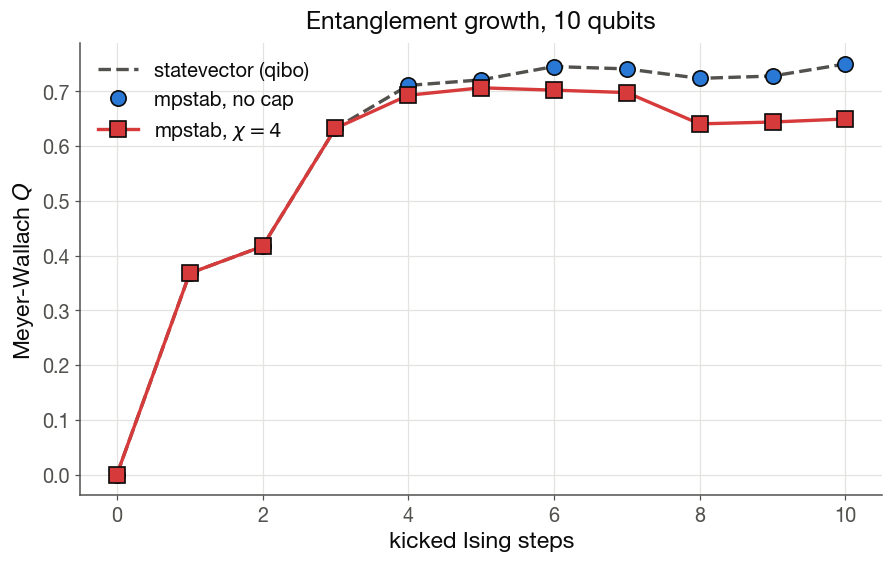

In [5]:
fig, ax = plt.subplots()
ax.plot(steps, exact, "--", color=COLORS["gray"], label="statevector (qibo)")
ax.plot(steps, full, "o", label=r"mpstab, no cap")
ax.plot(steps, capped, "s-", label=r"mpstab, $\chi = 4$")
ax.set_xlabel("kicked Ising steps")
ax.set_ylabel("Meyer-Wallach $Q$")
ax.set_title("Entanglement growth, 10 qubits")
ax.legend()
plt.show()

### Convergence with the bond dimension

How large must $\chi$ be? We fix a deep circuit (12 qubits, 8 steps) and plot the error $|Q_\chi - Q|$ against the exact value as the cap grows. The error drops by orders of magnitude once $\chi$ is large enough to hold the state's entanglement.

In [6]:
deep = KickedIsing(nqubits=12, n_steps=8, theta_h=0.8, theta_z=0.3)
exact_deep = float(meyer_wallach_entanglement(statevector(deep)))

bond_dimensions = [1, 2, 4, 8, 16, 32, 64]
errors = [
    abs(meyer_wallach_mps(HSMPO(deep, max_bond_dimension=chi, progress=False)) - exact_deep)
    for chi in bond_dimensions
]

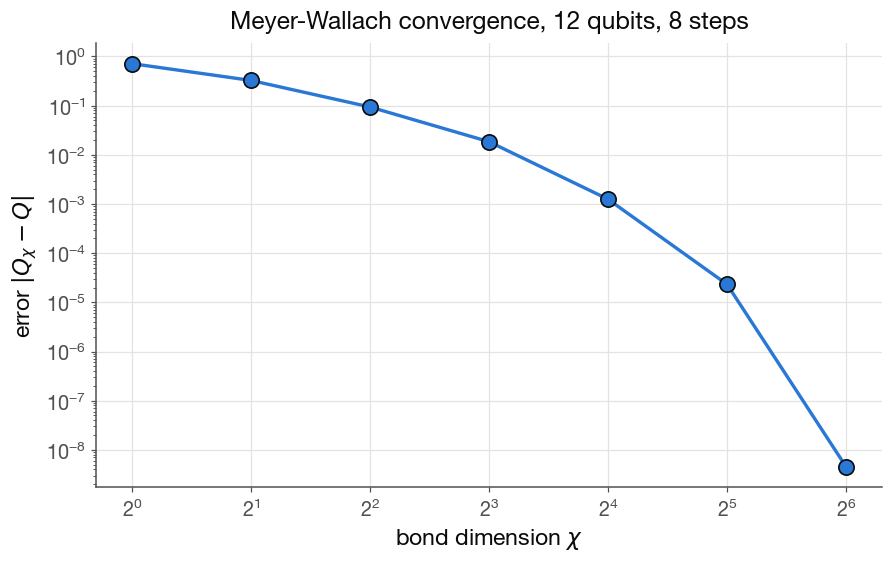

In [7]:
fig, ax = plt.subplots()
ax.plot(bond_dimensions, errors, "o-")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel(r"bond dimension $\chi$")
ax.set_ylabel(r"error $|Q_\chi - Q|$")
ax.set_title("Meyer-Wallach convergence, 12 qubits, 8 steps")
plt.show()

## Stabilizer Rényi entropy

The stabilizer Rényi entropy of order $\alpha$ measures how far a state is from the stabilizer states,

$$
M_\alpha(\psi) = \frac{1}{1 - \alpha} \log_2 \sum_{P} \frac{\langle\psi|P|\psi\rangle^{2\alpha}}{2^n},
$$

with the sum over all $4^n$ Pauli strings. It is zero exactly for stabilizer states. `stabilizer_renyi_entropy_mps` estimates the sum by sampling `n_samples` Pauli strings uniformly at random; pass a `seed` for reproducible results. Both functions return the total $M_\alpha$ in bits.

In [8]:
magic = KickedIsing(nqubits=6, n_steps=3, theta_h=0.8, theta_z=0.3)
hsmpo = HSMPO(magic, progress=False)

m2 = stabilizer_renyi_entropy_mps(hsmpo, alpha=2, n_samples=2000, seed=0)
m2_exact = float(stabilizer_renyi_entropy(statevector(magic), alpha=2))
print(f"mpstab (2000 samples): M2 = {m2:.3f}")
print(f"qibo   (exact)       : M2 = {m2_exact:.3f}")

mpstab (2000 samples): M2 = 3.389
qibo   (exact)       : M2 = 3.044


### Convergence with the number of samples

The estimate is random, so we repeat it over 6 seeds and plot the mean with its standard deviation as error bar. We do this for the magic circuit above and for a stabilizer version of it ($\theta_h = \pi/2$, $\theta_z = 0$), whose exact $M_2$ is 0. The spread shrinks like $1/\sqrt{K}$ with the number of samples $K$. The mean sits slightly above the exact value for small $K$: the Pauli sum is estimated without bias, but its logarithm is not, and this bias also fades as $K$ grows.

In [9]:
stabilizer = KickedIsing(nqubits=6, n_steps=3, theta_h=np.pi / 2, theta_z=0.0)
sample_sizes = [300, 1000, 3000]
seeds = range(6)

results = {}
for name, circuit in [("magic", magic), ("stabilizer", stabilizer)]:
    hsmpo = HSMPO(circuit, progress=False)
    estimates = [
        [stabilizer_renyi_entropy_mps(hsmpo, alpha=2, n_samples=k, seed=s) for s in seeds]
        for k in sample_sizes
    ]
    exact_m2 = float(stabilizer_renyi_entropy(statevector(circuit), alpha=2))
    results[name] = (exact_m2, np.mean(estimates, axis=1), np.std(estimates, axis=1))

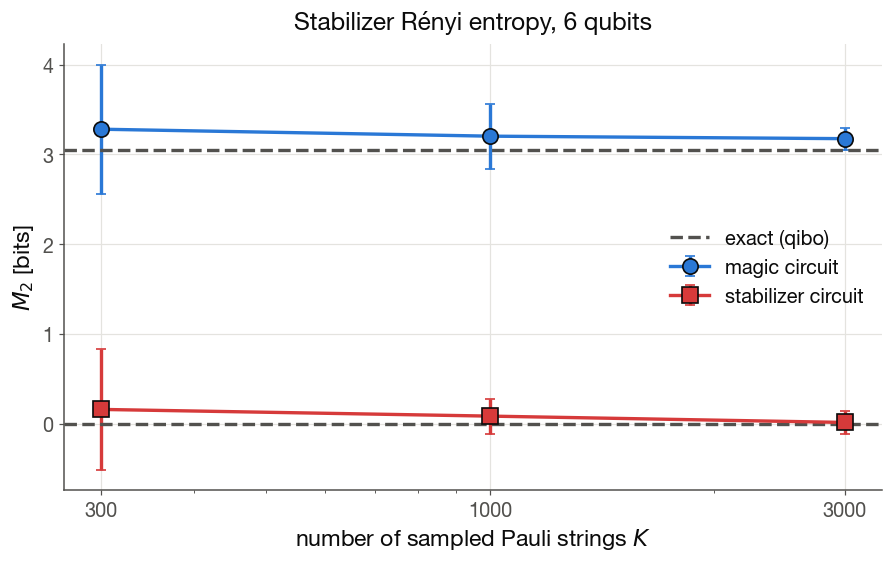

In [10]:
fig, ax = plt.subplots()
for (name, (exact_m2, mean, std)), marker in zip(results.items(), ["o", "s"]):
    ax.errorbar(sample_sizes, mean, yerr=std, fmt=marker + "-", label=f"{name} circuit")
    ax.axhline(exact_m2, ls="--", color=COLORS["gray"])
ax.plot([], [], "--", color=COLORS["gray"], label="exact (qibo)")
ax.set_xscale("log")
ax.set_xticks(sample_sizes, [str(k) for k in sample_sizes])
ax.set_xlabel("number of sampled Pauli strings $K$")
ax.set_ylabel(r"$M_2$ [bits]")
ax.set_title("Stabilizer Rényi entropy, 6 qubits")
ax.legend()
plt.show()

Uniform sampling has a limit: most Pauli strings have a vanishing expectation value, so the number of samples needed for a given precision grows exponentially with the number of qubits. For a stabilizer state only $2^n$ of the $4^n$ strings are nonzero; with too few samples none of them may be drawn, and the function then raises a `ValueError` asking for more samples. Use `stabilizer_renyi_entropy_mps` on small and medium registers, and increase `n_samples` until the spread over seeds is acceptable.

## Beyond the statevector: 50 qubits

`meyer_wallach_mps` only needs $3n$ contractions, so it scales to registers no statevector can hold. On a 50-qubit kicked Ising chain there is no exact reference, but we can check convergence ourselves: we repeat the computation for increasing $\chi$ and trust the result where the curves stop changing. Small caps underestimate the entanglement at large depth, while $\chi = 16$ and $\chi = 64$ agree up to about 7 steps; deeper circuits would need a larger $\chi$ to be trusted.

In [11]:
large_steps = range(1, 11)
large = {}
for chi in [4, 16, 64]:
    large[chi] = [
        meyer_wallach_mps(
            HSMPO(
                KickedIsing(nqubits=50, n_steps=n_steps, theta_h=0.8, theta_z=0.3),
                max_bond_dimension=chi,
                progress=False,
            )
        )
        for n_steps in large_steps
    ]

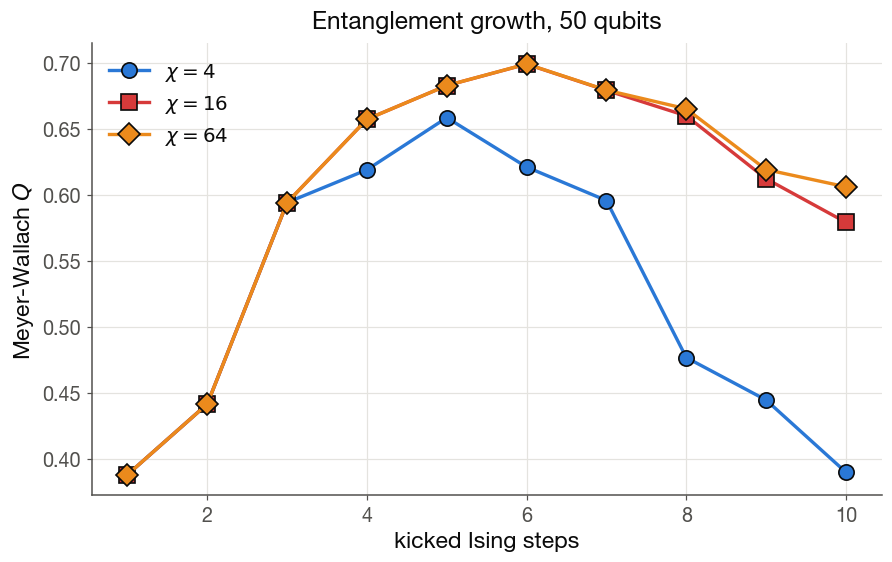

In [12]:
fig, ax = plt.subplots()
for (chi, values), marker in zip(large.items(), ["o", "s", "D"]):
    ax.plot(large_steps, values, marker + "-", label=rf"$\chi = {chi}$")
ax.set_xlabel("kicked Ising steps")
ax.set_ylabel("Meyer-Wallach $Q$")
ax.set_title("Entanglement growth, 50 qubits")
ax.legend()
plt.show()

## Summary

- `meyer_wallach_mps(hsmpo)` gives the Meyer-Wallach entanglement of an HSMPO state, exact up to the MPS truncation; increase `max_bond_dimension` until it stops changing.
- `stabilizer_renyi_entropy_mps(hsmpo, alpha, n_samples, seed)` estimates the stabilizer Rényi entropy by uniform Pauli sampling; repeat over seeds to get an error bar, and increase `n_samples` to shrink it.
- Both follow Qibo's conventions, so they can be compared directly with `meyer_wallach_entanglement` and `stabilizer_renyi_entropy` on a statevector.